## # Ironhack Data Analytics Bootcamp
**Author:** Erzsebet Fuzes  
**Cohort:** DAFT OCT2026  
**Topic:** EDA Univariate Analysis

## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


**Import and initial analysis:**


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

# Loading the Amazon UK product dataset (assuming the file name is "housing_price.csv")
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [9]:
# Display the first few rows of the dataset
print(f'Head of the dataframe:')
df.head()


Head of the dataframe:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
# Retrieving the number of rows and columns in the dataframe
print(f'Number of rows and columns in the dataframe:\n{df.shape}')

print('\n')
print('='*60)
print('\n')

# Displaying the data types of each column in the dataframe
print(f'Data types of each column: {df.dtypes}')


Number of rows and columns in the dataframe:
(2443651, 9)




Data types of each column: uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object


In [13]:
# Retrieving the unique data types present in the dataframe columns
print('The unique datatypes:')
list(set(df.dtypes.tolist()))


The unique datatypes:


[dtype('float64'),
 <StringDtype(storage='python', na_value=nan)>,
 dtype('bool'),
 dtype('int64')]

In [7]:
# Extracting column names with numerical data types from the dataframe
df.select_dtypes("number").columns
# csak a numerikus oszlopokat mutatja meg, mindegy, hogy float vagy integer


Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='str')

In [14]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)


uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64


---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---



In [21]:
# Unique values in the 'category':
df['category'].nunique()

296

In [73]:
# Frequency table for 'category':
frequency_table = df['category'].value_counts()

# Proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True)



print(f"Frequency table:\n\n  {frequency_table}")
print('\n')
print('='*60)
print('\n')
print(f"Proportion_table:\n\n {proportion_table}")



Frequency table:

  category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64




Proportion_table:

 category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
                                            ...   
Motorbike Chassis                         0.000044
Ale

---

Which are the top 5 most listed product categories?

- Sports & Outdoors
- Beauty
- Handmade Clothing, Shoes & Accessories
- Bath & Body
- Birthday Gifts

---
2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

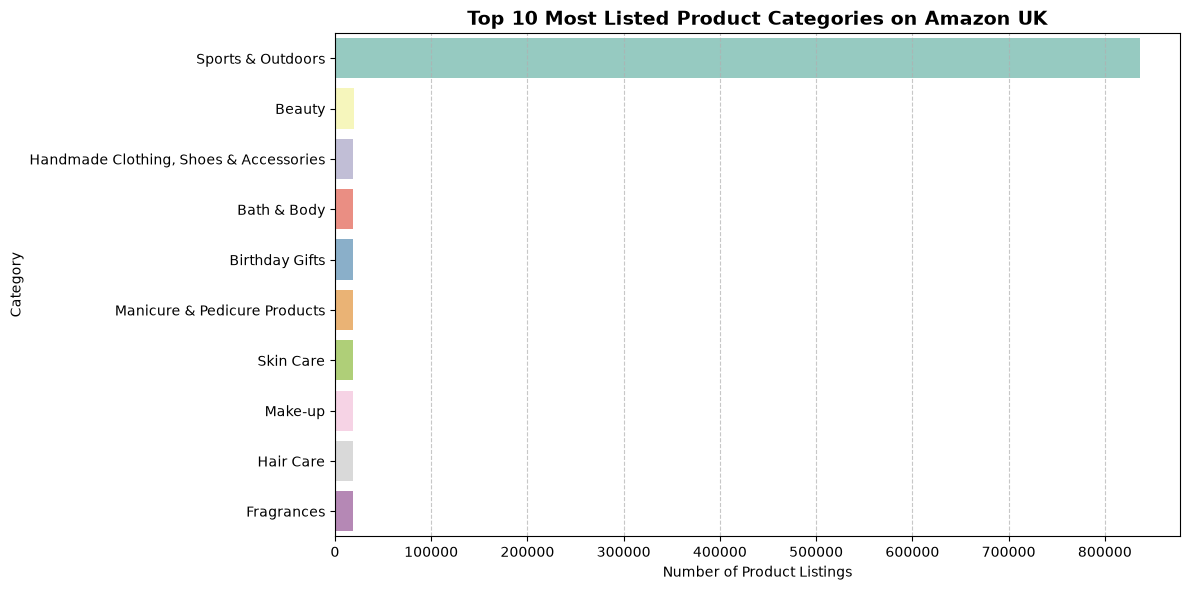

In [45]:
# Display the distribution of products across different categories using a bar chart. 
# If you face problems understanding the chart, do it for a subset of top categories.
# Create a subset of top categories
top10_categories = df['category'].value_counts().head(10)

# Bar chart megjelenítése
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top10_categories.values, 
    y=top10_categories.index, 
    hue=top10_categories.index,
    palette='Set3', 
    legend=False)

plt.title('Top 10 Most Listed Product Categories on Amazon UK', fontsize=14, fontweight='bold')
plt.xlabel('Number of Product Listings', fontsize=10)
plt.ylabel('Category', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

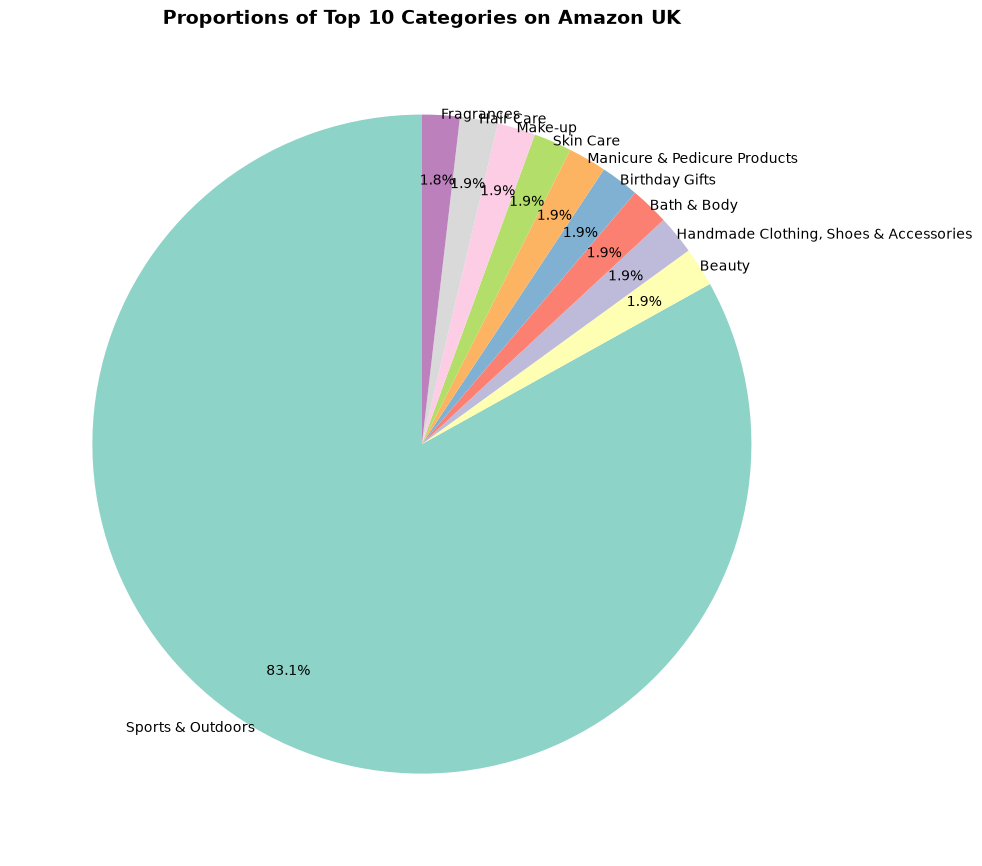

In [57]:
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
top10_categories = df['category'].value_counts().head(10)

# 2. Piechart
plt.figure(figsize=(10, 10))
# At a smaller size, the inscriptions were unreadable.

explode_settings = (0, 0, 0, 0, 0, 0, 0, 0, 0, 0)

top10_categories.plot.pie(
    autopct='%.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3"),
    explode=explode_settings,
    pctdistance=.8,      
    labeldistance=1     
)

plt.title("Proportions of Top 10 Categories on Amazon UK", fontsize=14, fontweight='bold')
plt.ylabel("")

plt.tight_layout()
plt.show()


---

**Does any category dominate the listings?**
- Yes, Sports & Outdoors

---




---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)? 

---



In [67]:
# Measures of Centrality:
# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

price_mean = df['price'].mean().round(3)
price_median = df['price'].median()
price_mode = df['price'].mode()[0]
print('='*60)
print('The mean/average of the price:')
print(price_mean)
print('\nThe median of the price:')
print(price_median)
print('\nThe mode of the price:')
print(price_mode)
print('='*60)
print('\nThe 10 most expensive products:')
df.sort_values(by='price', ascending=False)[['title', 'price', 'category']].head(10)


The mean/average of the price:
89.244

The median of the price:
19.09

The mode of the price:
9.99

The 10 most expensive products:


,title,price,category
2008013,HB FBA Test Treadmill,100000.00,Sports & Outdoors
1987238,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,77752.00,Desktop PCs
1905315,Abaodam decor christmas ornaments Desk Ornamen...,24674.59,Garden Storage & Housing
1408966,BM4445-FI1-01200R10-03-E03 Driver,23482.73,Scanners & Accessories
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,22933.42,Projectors
1490285,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00,Sports & Outdoors
1490286,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00,Sports & Outdoors
1907271,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing
1907273,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing
1907272,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing



---

**What's the average price point of products listed? How does this compare with the most common price point (mode)?**
- If the average price is 89.24 and the most common price (mode) is 9.99, it means that the dataset contains extremely expensive products. ()
- Therefore, the price distribution is right-skewed.
- This is also shown by the median—the price of the "middle" product (unaffected by outliers):
this is also shown by the median, which is 19.09
---




2. **Measures of Dispersion**:
   
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?



In [70]:
#  - Determine the variance, standard deviation, range, and interquartile range for product `price`.

price_var = df['price'].var().round(2)
price_std_dev = df['price'].std().round(2)
price_range = df['price'].max() - df['price'].min()
price_quantiles = df['price'].quantile([0.25, 0.5, 0.75])

print('='*60)
print('The variance of the price:')
print(price_var)
print('\nThe standard deviation of the price:')
print(price_std_dev)
print('\nThe range of the price:')
print(price_range)
print('\nThe interquartile range of the price:')
print(price_quantiles)


The variance of the price:
119445.49

The standard deviation of the price:
345.61

The range of the price:
100000.0

The interquartile range of the price:
0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64



---
**How varied are the product prices? Are there any indicators of a significant spread in prices?**
Prices shows extreme dispersion and volatility

Product prices exhibit extreme volatility and significant dispersion because of extreme outliers at the top of the spectrum.

1. Indicators of extreme dispersion
- Quite high variance (119,445.49) and standard deviation (approx. 345.61):
compare to the two value indicates that price data is widely dispersed around the central value.

- Huge range (£100,000.00):
The difference between the lowest and highest price reaches 100,000, confirm that the Amazon features products with exceptionally high prices.

-Strong right-skewness (based on a comparison of the interquartile range and the total range):
Interquartile range (IQR): 45.99 – 9.99 = £36.00. -- 50% of the products (the middle range) are priced between 9.99 (25th percentile) and 45.99 (75th percentile).
While 75% of the products are priced below £45.99, the full price spectrum extends all the way up to 100,000. 

2. Business Conclusion
The vast majority of products are inexpensive and centered around mid-range, everyday items (for instance, the most frequent price is 9.99); however, a small proportion of premium or luxury goods—as well as specialized industrial equipment—significantly inflates aggregate metrics such as standard deviation and the mean.

---


---
3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.

    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

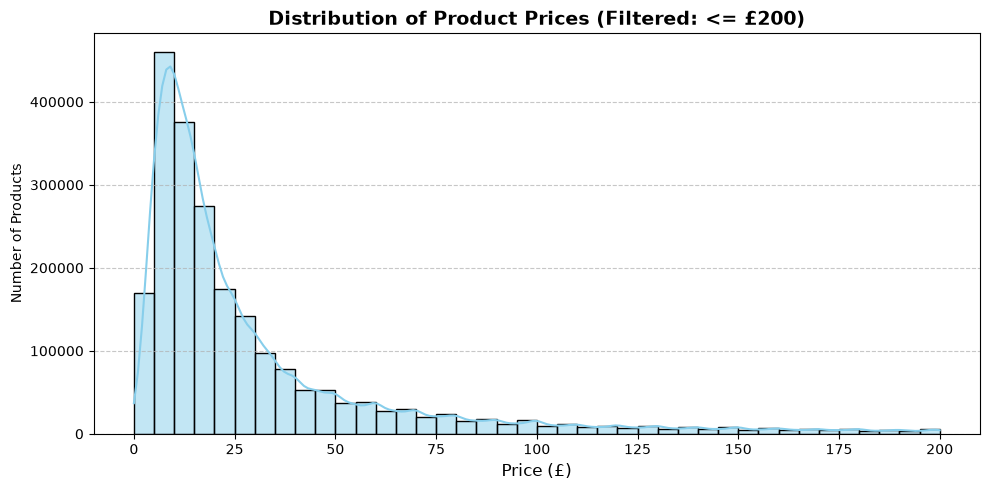

In [75]:

# Histogram for the vast majority of products (0 – 200 GBP)
plt.figure(figsize=(10, 5))
sns.histplot(df[df['price'] <= 200]['price'], bins=40, kde=True, color='skyblue')

plt.title('Distribution of Product Prices (Filtered: <= £200)', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Number of Products', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

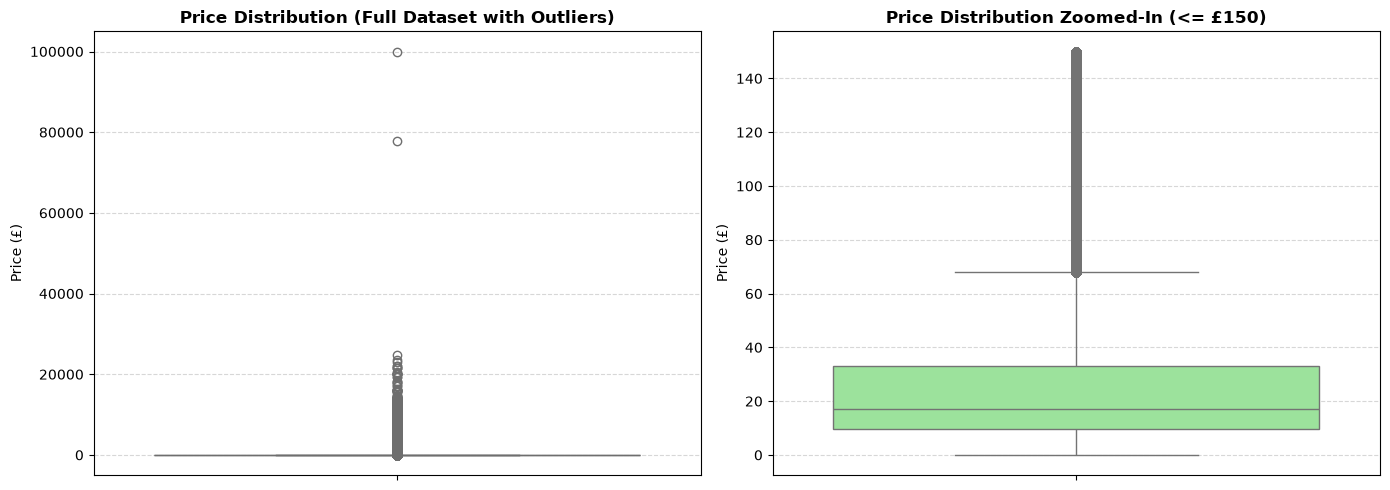

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Box plot of the full dataset (showing the record outlier of £100,000)
sns.boxplot(y=df['price'], ax=axes[0], color='lightcoral')
axes[0].set_title('Price Distribution (Full Dataset with Outliers)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Price (£)', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Filtered Box Plot for the realistic range (e.g., £0 – £150) for better visibility of quartiles and the median
sns.boxplot(y=df[df['price'] <= 150]['price'], ax=axes[1], color='lightgreen')
axes[1].set_title('Price Distribution Zoomed-In (<= £150)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Price (£)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
**Is there a specific price range where most products fall?**
Yes, the vast majority of products in in the 5 and 35 GBP price range (mode is 9.99 GBP, median is 19.09 GBP)

**Why are raw charts difficult to interpret, and how can this be addressed?**
Extreme price outliers (reaching as high as 100,000 GBP) cause a right-skew, which stretches the axes.a Box Plot felső részén megjelenő pontok sora (és a £100 000-os csúcsérték) egyértelműen mutatja a jelentős kiugró értékeket (outliers). 

**Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.**
The series of points appearing at the top of the box plot (as well as the peak value of 100,000 GBP) clearly indicate significant outliers.

---

---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?



In [84]:
# Measures of Centrality
mean_rating = df['stars'].mean().round(2)
median_rating = df['stars'].median().round(2)
mode_rating = df['stars'].mode()[0].round(2)

print(f"Mean Rating: {mean_rating:}")
print(f"Median Rating: {median_rating:}")
print(f"Mode Rating: {mode_rating:}")

print("="*60)
# Dataframe - only the rated products
rated_products = df[df['stars'] > 0]['stars']

print("Mean of rated products:", rated_products.mean().round(2))
print("Median of rated products:", rated_products.median().round(2))
print("Mode of rated products:", rated_products.mode()[0])


Mean Rating: 2.15
Median Rating: 0.0
Mode Rating: 0.0
Mean of rated products: 4.32
Median of rated products: 4.4
Mode of rated products: 4.5


**How do customers generally rate products? Is there a common trend?**
1. The vast majority of products have NO ratings (a rating of 0.0).
The mode (0.0) and the median (0.0) indicate that more than half (at least 50%) of the products in the Amazon UK dataset have a rating of 0.
This means that the overwhelming majority of the listed products have not yet received a single customer review or star rating (or have not yet been rated within the Amazon system).

2. What does the average of 2.15 signify?
Since at least half of the products appear in the dataset with 0.0 stars, these zero values pull the average for the entire dataset down significantly (to 2.15). Products that do receive ratings generally perform well (scoring between 4.0 and 5.0 stars); however, the overall picture is skewed by the sheer volume of unrated (0.0) products.

============================================================

When examining only those products **that have received a rating** (rating > 0), the resulting metrics indicate the following:

Mean of rated products: 4.32
Median of rated products: 4.4
Mode of rated products: 4.5
In short: while the dataset contains a large number of unrated products, customers are overwhelmingly very satisfied with the items they actually purchase and rate.

**Business Insight:**
Strong left-skewness in customer feedback: On Amazon UK, for products that have actually been rated, customer feedback is heavily concentrated at the top end of the scale (between 4.0 and 5.0 stars).

With a median of 4.4 and a mode of 4.5, a rating of 4.3–4.5 stars for a product on Amazon UK is not considered exceptional.

**Business Positioning:**
If a product’s rating on the platform falls below 4.0 stars, it effectively places that item in the bottom tier, given that the average for competitors is above 4.32.



In [91]:
# Measures of Dispersion
var_rating = df['stars'].var().round(2)
std_rating = df['stars'].std().round(2)
q25, q75 = df['stars'].quantile(0.25), df['stars'].quantile(0.75)
iqr_rating = q75 - q25

print(f"Variance: {var_rating:}")
print(f"Standard Deviation: {std_rating:}")
print(f"IQR: {iqr_rating:} (25%: {q25:}, 75%: {q75:})")

print("="*60)


var_real_rating = rated_products.var().round(2)
std_real_rating = rated_products.std().round(2)
real_q25, real_q75 = rated_products.quantile(0.25), rated_products.quantile(0.75)
iqr_real_rating = real_q75 - real_q25

print(f"Variance of rated products: {var_real_rating:}")
print(f"Standard Deviation of rated products: {std_real_rating:}")
print(f"IQR of of rated products: {iqr_real_rating:} (25%: {real_q25:}, 75%: {real_q75:})")

Variance: 4.82
Standard Deviation: 2.19
IQR: 4.4 (25%: 0.0, 75%: 4.4)
Variance of rated products: 0.31
Standard Deviation of rated products: 0.56
IQR of of rated products: 0.5 (25%: 4.1, 75%: 4.6)


---
**Are the ratings consistent, or is there a wide variation in customer feedback?**

Based on the raw data, ratings appear to fluctuate; however, this is merely a consequence of the high proportion of products with no ratings (0.0).
There is a massive spread and inconsistency in the data.
The reason: more than 50% of the products in the table have received zero reviews (0.0).
IQR: 4.4 (25%: 0.0, 75%: 4.4)
The high number of zero values significantly skews the statistics away from the products that have actually been reviewed.

Based on actual customer feedback, the ratings are remarkably consistent. On Amazon UK, customers provide predominantly positive reviews: the majority of products consistently fall within the high 4.1–4.6 star range, with an extremely low standard deviation (0.56).
Standard Deviation (0.56): The standard deviation is extremely low. 
IQR (0.50): The middle 50\% of the products fall within a narrow range between 4.1 and 4.6 stars.

In [94]:
# Skewness & Kurtosis
skew_rating = df['stars'].skew().round(2)
kurt_rating = df['stars'].kurt().round(2)

print(f"Skewness: {skew_rating:}")
print(f"Kurtosis: {kurt_rating:}")

print("="*60)
skew_rating = rated_products.skew().round(2)
kurt_rating = rated_products.kurt().round(2)

print(f"Skewness of rated products: {skew_rating:}")
print(f"Kurtosis of rated products: {kurt_rating:}")



Skewness: 0.08
Kurtosis: -1.93
Skewness of rated products: -2.38
Kurtosis of rated products: 9.78


---
**Are the ratings normally distributed, or do they lean towards higher or lower values?**

No. Neither the raw dataset nor the group of products that actually received ratings follows a classic normal distribution (bell curve). 
Actual customer feedback leans significantly toward higher values (4.0–5.0 stars). On Amazon UK, customers are overwhelmingly satisfied with the products they purchase; low-score ratings are a distinct rarity.

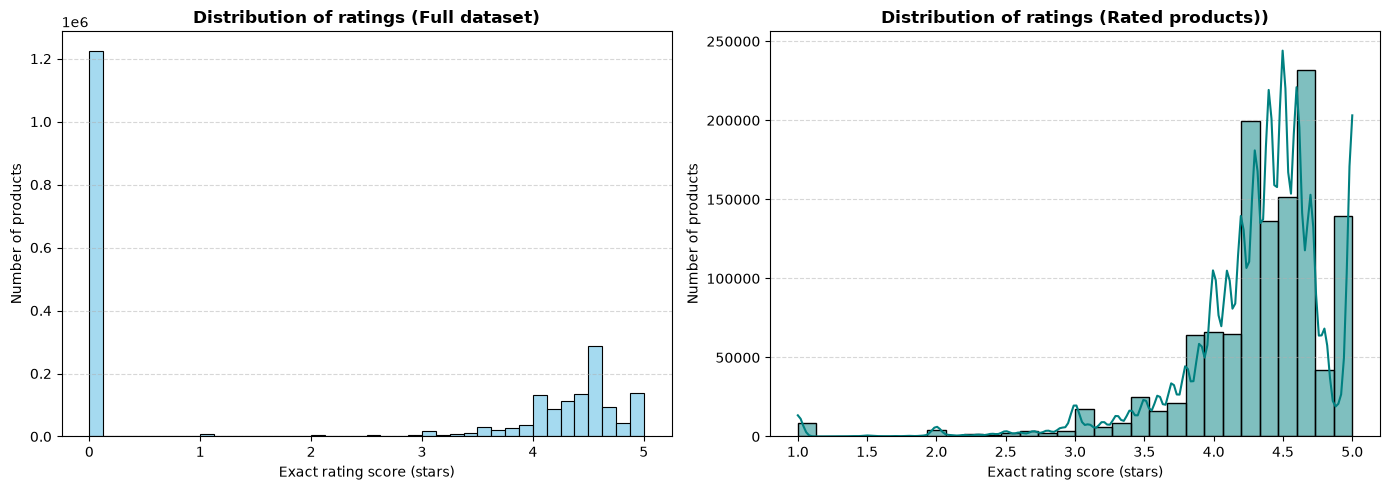

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram for the entire data set (Includes 0.0 unrated products)
sns.histplot(df['stars'], bins=40, kde=False, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Distribution of ratings (Full dataset)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Exact rating score (stars)', fontsize=10)
axes[0].set_ylabel('Number of products', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Histogram for rated roducts
rated_df = df[df['stars'] > 0]
sns.histplot(rated_df['stars'], bins=30, kde=True, color='teal', edgecolor='black', ax=axes[1])
axes[1].set_title('Distribution of ratings (Rated products))', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Exact rating score (stars)', fontsize=10)
axes[1].set_ylabel('Number of products', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()




---
**Is there a specific rating that is more common?**

In the **full dataset** (chart on the left): A rating of 0 is the most frequent and dominant (for over 1.2 million products). This is because a significant portion of the products has not yet received a single customer rating.

For products that **have been rated** (chart on the right): The peaks fall precisely within the 4.3 to 4.7 range. There is also a smaller uptick around 5.0, but the majority of products are concentrated in the 4.3–4.6 interval.


---

## Business Centric Report - Amazon UK product catalog - Pricing and ratings of products

***1. Business context:***
The purpose of the analysis is to examine the price structure and customer satisfaction indicators for products available on the Amazon UK platform (approximately 2.44 million data entries).

***2.Key Business Findings***

**2.1 Product Pricing Dynamics and Price Structure**
- High concentration of prices in the cost-effective range:
The most frequent list price (mode) is exactly 9.99 GBP, while 50% of the products fall within the 9.99 GBP to 45.99 GBP range (IQR = 36.00 GBP, median = 19.09 GBP). The vast majority of the product offering consists of everyday, budget-friendly, and mid-range items.
- Extreme outliers in the high-price segment (right-skewed distribution):
The average price (89.24 GBP) differs significantly from the median (19.09 GBP), and the standard deviation reaches 345.61 GBP across the full price range of 100,000.00 GBP. This confirms the presence of isolated, extremely high-priced premium or industrial products in the catalog, which pull the average—a metric sensitive to skew—upward.

**2.2 Customer Ratings and Satisfaction Patterns**
- Bipolar Catalog Structure:
In the raw dataset, more than 50% of the products have a rating of 0.0 stars (Median = 0.0, Mode = 0.0, Mean = 2.15). This indicates that a significant portion of the listed inventory consists of brand-new products or items that have not yet received any ratings.
- High Baseline Customer Satisfaction (stars > 0):
When examining only the products that have actually been rated, customer satisfaction is notably high and consistent:
    - Average rating: 4.32 stars
    - Median: 4.40 stars
    - Mode: 4.50 stars
-Consistency in Feedback:
The standard deviation for the rated products is extremely low (0.56), with 50% of the items concentrated within a narrow range of 4.10 to 4.60 stars. The distribution is strongly left-skewed (Skewness = -2.38) and highly peaked (Kurtosis = 9.78), meaning that low ratings (1–3 stars) are rare exceptions.